# 01 · Official labels and the benchmark split

Images come from [`Voxel51/FloorPlanCAD`](https://huggingface.co/datasets/Voxel51/FloorPlanCAD) on Hugging Face, but that copy's class names are scrambled (sinks are called `wardrobe`, toilets `escalator`, windows `stair`, …). So gold labels come from the **original** dataset instead:

1. Download the official test archive from [floorplancad.github.io](https://floorplancad.github.io/) (~2 GB), match every Voxel51 image to its official drawing pixel for pixel, and read the official class id and instance id of every element in the SVGs → `data/official_counts.json`. Skipped if that file already exists.
2. Sanity-check the official class order.
3. Show what each Voxel51 name really is.
4. Build the building-level train / test split.

Free: no model calls.

In [1]:
import json, os, re, subprocess, sys, tarfile
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

HERE = Path.cwd()
if not (HERE / "fp_common.py").exists():
    HERE = Path("experiments/floorplancad-symbol-counting").resolve()
os.chdir(HERE)
sys.path.insert(0, str(HERE))

import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

import fp_common as fc

NAMES = fc.OFFICIAL_NAMES
COUNTS = fc.DATA / "official_counts.json"
ARCHIVE = fc.DATA / "official"
TEST_ARCHIVE = "1jxpYgxnLUbXEzMOsjaMPQFSuvmvHimiZ"  # Google Drive id of the 'Test set' link on floorplancad.github.io
samples = fc.load_samples()

/opt/homebrew/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Official instance counts per tile
File names repeat across the official archives, so each Voxel51 image is matched by pixels (correlation of 128×128 greyscale) before reading its SVG.

In [2]:
def read_svg(path):
    inst, prims = defaultdict(set), Counter()
    for m in re.finditer(r'<\w+[^>]*?semantic-id="(\d+)"[^>]*', path.read_text()):
        s = int(m.group(1)); prims[s] += 1
        i = re.search(r'instance-id="(-?\d+)"', m.group(0))
        if i and int(i.group(1)) >= 0:
            inst[s].add(int(i.group(1)))
    return {s: {"prims": prims[s], "n": len(inst[s])} for s in prims}

def sig(p):
    return np.asarray(Image.open(p).convert("L").resize((128, 128)), float).ravel()

def match(x):
    tile = Path(x["filepath"]).stem
    v = sig(fc.image_path(x))
    corr, best = max(((np.corrcoef(v, sig(p))[0, 1], p) for p in ARCHIVE.glob(f"*/{tile}.png")), key=lambda t: t[0])
    return tile, corr, read_svg(best.with_suffix(".svg"))

if not COUNTS.exists():
    arch_dir = ARCHIVE / TEST_ARCHIVE
    if not any(arch_dir.glob("*.svg")):
        blob = ARCHIVE / f"{TEST_ARCHIVE}.tar.xz"
        if not blob.exists():
            ARCHIVE.mkdir(parents=True, exist_ok=True)
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gdown"], check=True)
            subprocess.run(["gdown", TEST_ARCHIVE, "-O", str(blob)], check=True)
        arch_dir.mkdir(exist_ok=True)
        with tarfile.open(blob, "r:xz") as t:
            t.extractall(arch_dir)
    fc.prefetch(samples)
    with ThreadPoolExecutor(16) as ex:
        matched = list(tqdm(ex.map(match, samples), total=len(samples), desc="match"))
    print(f"{len(matched)} tiles matched · min pixel correlation {min(c for _, c, _ in matched):.6f}")
    COUNTS.write_text(json.dumps({t: sem for t, _, sem in matched}))

official = {t: {int(k): v for k, v in sem.items()} for t, sem in json.loads(COUNTS.read_text()).items()}
print(len(official), "tiles with official counts")

5308 tiles with official counts


## 2. Official classes: element and instance counts
Stuff classes (wall, curtain wall, railing, …) have drawing elements but no instances. Ids 1 and 2 showing zero instances confirms the wall-first class order.

In [3]:
tot_p, tot_n = Counter(), Counter()
for sem in official.values():
    for s, d in sem.items():
        tot_p[s] += d["prims"]; tot_n[s] += d["n"]
pd.DataFrame([{"id": s, "official name": NAMES[s - 1], "drawing elements": tot_p[s], "instances": tot_n[s]}
              for s in sorted(tot_p)]).set_index("id")

,official name,drawing elements,instances
id,,,
1,wall,322869,0
2,curtain wall,48794,0
3,single door,51566,7808
4,double door,49342,4261
5,sliding door,19075,1910
6,folding door,665,41
7,revolving door,124,1
8,rolling door,6,2
9,window,45698,6026


## 3. What each Voxel51 name really is
For each Voxel51 label: the official class whose per-tile instance count most often equals the Voxel51 box count. The last column is our first attempt, repairing names by eye from crops: it got 6 of the 9 classes we use right.

In [4]:
BY_EYE = {"double_door": "door", "sliding_door": "door", "stair": "window", "window": "window", "bath": "sink",
          "escalator": "toilet", "parking": "staircase", "class_31": "elevator", "elevator": "urinal", "sink": "stove",
          "squat_toilet": "bathtub"}
hits, tiles = defaultdict(Counter), Counter()
for x in samples:
    sem = {s: v["n"] for s, v in official[Path(x["filepath"]).stem].items()}
    for lab, n in Counter(d["label"] for d in x["ground_truth"]["detections"]).items():
        tiles[lab] += 1
        for s, m in sem.items():
            hits[lab][s] += m == n
rows = []
for lab in sorted(tiles, key=lambda l: -tiles[l]):
    s, h = hits[lab].most_common(1)[0]
    guess = BY_EYE.get(lab)
    rows.append({"Voxel51 name": lab, "tiles": tiles[lab], "official class": NAMES[s - 1], "exact-count match": f"{h / tiles[lab]:.0%}",
                 "by-eye guess": guess or "", "by-eye right?": "" if not guess else NAMES[s - 1] in fc.OFFICIAL_GROUPS[guess]})
pd.DataFrame(rows).set_index("Voxel51 name")

,tiles,official class,exact-count match,by-eye guess,by-eye right?
Voxel51 name,,,,,
wall,4710,double door,19%,,
double_door,2096,single door,100%,door,True
sliding_door,2075,double door,100%,door,True
stair,2052,window,100%,window,True
bath,1216,airconditioner,100%,sink,False
parking,1189,stairs,100%,staircase,True
window,944,sliding door,100%,window,False
escalator,802,toilet,100%,toilet,True
railing,741,stairs,25%,,


One tile, both ways:

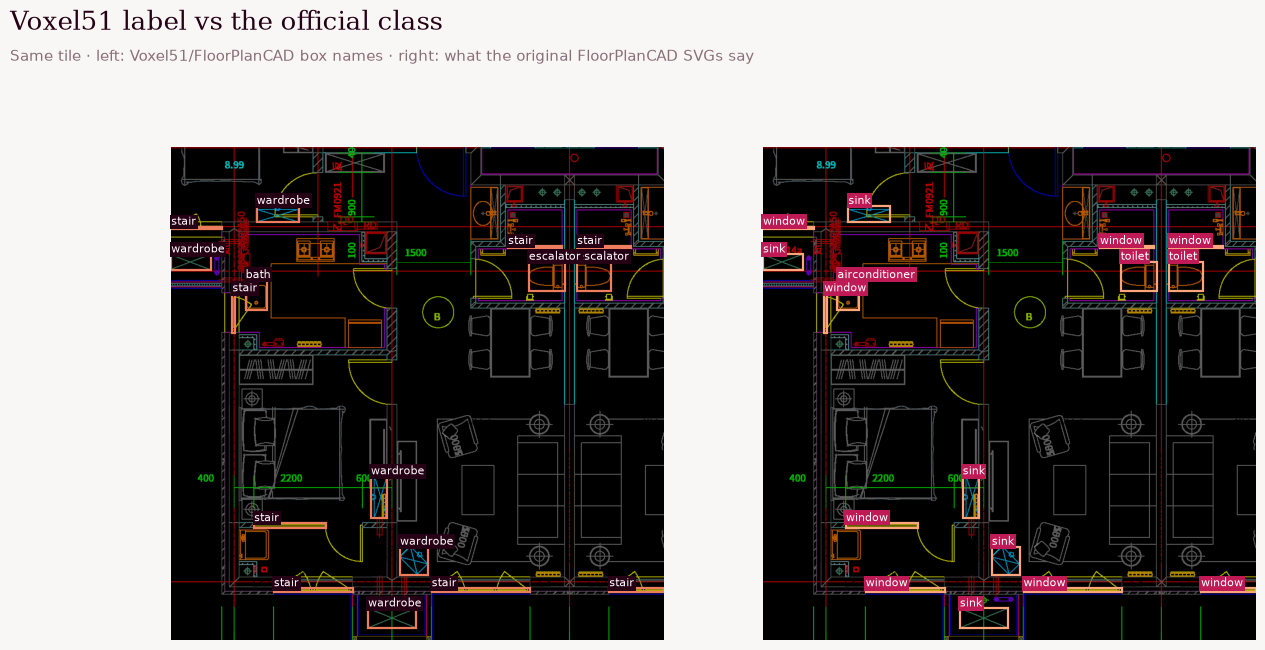

In [5]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import fw_utils as fv
fv.apply_theme()
true_name = {r["Voxel51 name"]: r["official class"] for r in rows}
want = {"bath", "escalator", "stair", "wardrobe"}
x = max(samples, key=lambda s: len(want & {d["label"] for d in s["ground_truth"]["detections"]}))
img = Image.open(fc.image_path(x)).convert("RGB")
W, H = img.size
fig, axes = plt.subplots(1, 2, figsize=(14, 7.6))
fv._title(fig, "Voxel51 label vs the official class", "Same tile · left: Voxel51/FloorPlanCAD box names · right: what the original FloorPlanCAD SVGs say")
for ax, use_true in zip(axes, (False, True)):
    ax.imshow(img); ax.axis("off")
    for d in x["ground_truth"]["detections"]:
        if d["label"] not in want:
            continue
        bx, by, bw, bh = d["bounding_box"]
        ax.add_patch(Rectangle((bx * W, by * H), bw * W, bh * H, fill=False, lw=1.6, ec=fv.ORANGE if use_true else fv.CORAL))
        ax.text(bx * W, by * H - 4, true_name[d["label"]] if use_true else d["label"], color="white", fontsize=8,
                bbox=dict(fc=fv.MAGENTA if use_true else fv.INK, ec="none", pad=1.2))
fv.show(fig, "voxel51_vs_official")

## 4. Benchmark split
Buildings are split 80 / 20 so no building is in both. Per tile: one counting question (a class present 1–12 times) and one presence question (balanced yes / no). Our classes group the official ones: doors = all six door types, windows = window / bay / blind, toilets = toilet / squat toilet, bathtubs = bath / bath tub.

In [6]:
print(fc.build())
test = fc.load_split("test")
pres = [r for r in test if r["kind"] == "presence"]
print(f"test: {len(test) - len(pres)} counting + {len(pres)} presence ({sum(r['answer'] == 'yes' for r in pres) / len(pres):.0%} yes) "
      f"from {len({r['building'] for r in test})} buildings")
pd.Series(Counter(r["cls"] for r in test)).sort_values(ascending=False).rename("test questions").to_frame()

{'train': 6219, 'test': 1000}
test: 495 counting + 505 presence (49% yes) from 185 buildings


,test questions
door,307
window,191
staircase,125
toilet,78
elevator,78
urinal,63
sink,60
bathtub,50
stove,48
